# 03 微调策略比较（E2）

固定 E1 选定骨干，比较 Freeze、Partial、Full。策略学习率由 base.yaml 的 training.lr_by_strategy 统一提供；记录真实使用的值。

**前置条件：** 完成 E1 并保存选择；每个候选重新从 ImageNet 权重初始化，不继承上个候选权重。

全部模型选择只依据 **PlantVillage 验证集 Macro-F1**，本 Notebook 不读取 PlantVillage 测试图片或 PlantDoc。训练参数来自配置，默认 224×224、batch size 16、最多 10 轮、AdamW、交叉熵与 Early Stopping；改变配置前先记录理由。

`RUN_TRAINING=False` 时只读取配置和已有记录，不下载权重或训练。打开训练后，已完成且配置和数据指纹一致的候选自动跳过；未完成候选采用新的 run_id 重新训练，旧中断记录仍可识别。


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def find_project_root():
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        for root in (candidate, candidate / "plant-disease-project"):
            if (root / "configs" / "base.yaml").is_file():
                return root
    raise FileNotFoundError("请在项目根目录或 notebooks 目录打开本 Notebook。")


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import load_config, load_labels

BASE = load_config(PROJECT_ROOT / "configs" / "base.yaml")
EXPERIMENTS = load_config(PROJECT_ROOT / "configs" / "experiments.yaml")
LABELS = load_config(PROJECT_ROOT / "configs" / "labels.yaml")
CLASS_NAMES = [item["label"] for item in load_labels(PROJECT_ROOT)]
assert len(CLASS_NAMES) == 8 and len(set(CLASS_NAMES)) == 8
assert [item["label_index"] for item in LABELS["classes"]] == list(range(8))
print("项目目录：", PROJECT_ROOT)
print("类别数量：", len(CLASS_NAMES), "；随机种子：", BASE["seed"])


项目目录： /Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片病害识别与真实场景泛化优化研究/plant-disease-project
类别数量： 8 ；随机种子： 42


## 1. 查看计划与运行状态

先确认候选和基础配置。MPS 可用时优先使用，必要时回退 CPU。每个正式实验有独立目录，保存实际配置、标签、数据指纹、环境、状态、最佳权重和历史；不得把烟测结果用作模型选择。


In [7]:
from src.experiments import run_stage, stage_results, run_statuses, select_best, selected_run

STAGE = "E2"
RUN_TRAINING = True
SAVE_SELECTION = True

print("阶段：", STAGE)
print("候选：", EXPERIMENTS.get("finetuning_strategies"))
print("基础训练参数：")
display(BASE["training"])
print("策略学习率：", BASE["training"].get("lr_by_strategy"))
print("已选择骨干：", EXPERIMENTS.get("selected_backbone"))
print("已选择微调：", EXPERIMENTS.get("selected_finetuning"))
print("已选择增强：", EXPERIMENTS.get("selected_augmentation"))
display(pd.DataFrame(run_statuses(PROJECT_ROOT)))


阶段： E2
候选： ['freeze', 'partial', 'full']
基础训练参数：


{'epochs': 10,
 'batch_size': 16,
 'optimizer': 'AdamW',
 'lr': 0.001,
 'lr_by_strategy': {'freeze': 0.001, 'partial': 0.0001, 'full': 0.0001},
 'weight_decay': 0.0001,
 'early_stopping': True,
 'patience': 3,
 'num_workers': 0,
 'monitor': 'val_macro_f1'}

策略学习率： {'freeze': 0.001, 'partial': 0.0001, 'full': 0.0001}
已选择骨干： efficientnet_b0
已选择微调： None
已选择增强： None


,run_id,stage,model,finetuning,augmentation,status,smoke_test,epochs_completed,seconds,error
0,e1_efficientnet_b0_freeze_basic_s42_20261021T0...,E1,efficientnet_b0,freeze,basic,completed,False,10,564.835715,None
1,e1_mobilenet_v2_freeze_basic_s42_20261021T0506...,E1,mobilenet_v2,freeze,basic,completed,False,10,463.776880,None
2,e1_resnet18_freeze_basic_s42_20261021T045915_a...,E1,resnet18,freeze,basic,completed,False,10,427.105395,None
3,e2_efficientnet_b0_freeze_basic_s42_20261021T0...,E2,efficientnet_b0,freeze,basic,completed,False,10,598.054591,None
4,e2_efficientnet_b0_full_basic_s42_20261021T054...,E2,efficientnet_b0,full,basic,completed,False,7,1276.950187,None
5,e2_efficientnet_b0_partial_basic_s42_20261021T...,E2,efficientnet_b0,partial,basic,completed,False,8,501.635882,None
6,run_20261021T042510_f673d06c,E1,resnet18,freeze,basic,completed,True,1,1.024261,None


## 2. 运行本阶段训练

确认配置后，在上一格把 `RUN_TRAINING` 改为 `True`，重新运行上一格，再运行本格。训练过程可能持续较久；完成后查看下一节真实结果。训练异常会保留失败状态；内核被强制关闭时，状态和不完整文件仍可识别，重新运行会建立新实验。


In [4]:
prerequisite_ready = True
try:
    prerequisite_run = selected_run(PROJECT_ROOT, "E1")
    print("上阶段选定实验：", prerequisite_run.name)
except (ValueError, FileNotFoundError) as error:
    prerequisite_ready = False
    print("请先完成上一阶段并保存选择：", error)

if not RUN_TRAINING:
    print("训练关闭：目前只展示计划与已有结果。")
elif not prerequisite_ready:
    print("前置选择尚未完成，暂不训练。")
else:
    for run_dir in run_stage(PROJECT_ROOT, STAGE):
        print("已完成：", run_dir.name)


上阶段选定实验： e1_efficientnet_b0_freeze_basic_s42_20261021T051406_4c08b7
e2_efficientnet_b0_freeze_basic_s42_20261021T052651_5ad9ff | epoch 1: train_loss=0.5009, val_macro_f1=0.8632
e2_efficientnet_b0_freeze_basic_s42_20261021T052651_5ad9ff | epoch 2: train_loss=0.2495, val_macro_f1=0.9044
e2_efficientnet_b0_freeze_basic_s42_20261021T052651_5ad9ff | epoch 3: train_loss=0.2021, val_macro_f1=0.9257
e2_efficientnet_b0_freeze_basic_s42_20261021T052651_5ad9ff | epoch 4: train_loss=0.1796, val_macro_f1=0.9254
e2_efficientnet_b0_freeze_basic_s42_20261021T052651_5ad9ff | epoch 5: train_loss=0.1662, val_macro_f1=0.9378
e2_efficientnet_b0_freeze_basic_s42_20261021T052651_5ad9ff | epoch 6: train_loss=0.1569, val_macro_f1=0.9351
e2_efficientnet_b0_freeze_basic_s42_20261021T052651_5ad9ff | epoch 7: train_loss=0.1453, val_macro_f1=0.9394
e2_efficientnet_b0_freeze_basic_s42_20261021T052651_5ad9ff | epoch 8: train_loss=0.1358, val_macro_f1=0.9473
e2_efficientnet_b0_freeze_basic_s42_20261021T052651_5ad9ff |

## 3. 汇总完成的实验与训练曲线

仅汇总当前八类、当前清单和当前阶段参数一致的已完成正式实验。`val_macro_f1` 是最佳验证轮次对应指标，训练耗时按实际记录读取。尚无结果时不生成占位指标；中断训练不参与比较。


,run_id,stage,model,finetuning,augmentation,seed,lr,val_macro_f1,val_accuracy,val_loss,best_epoch,epochs_completed,seconds,dataset_fingerprint
0,e2_efficientnet_b0_full_basic_s42_20261021T054...,E2,efficientnet_b0,full,basic,42,0.0001,0.993843,0.995583,0.016419,4,7,1276.950187,65e16a548fb193b9d39fdb5114591eeb9fd90d17afbfa6...
1,e2_efficientnet_b0_partial_basic_s42_20261021T...,E2,efficientnet_b0,partial,basic,42,0.0001,0.985481,0.988074,0.047014,5,8,501.635882,65e16a548fb193b9d39fdb5114591eeb9fd90d17afbfa6...
2,e2_efficientnet_b0_freeze_basic_s42_20261021T0...,E2,efficientnet_b0,freeze,basic,42,0.0010,0.950244,0.960247,0.121426,10,10,598.054591,65e16a548fb193b9d39fdb5114591eeb9fd90d17afbfa6...


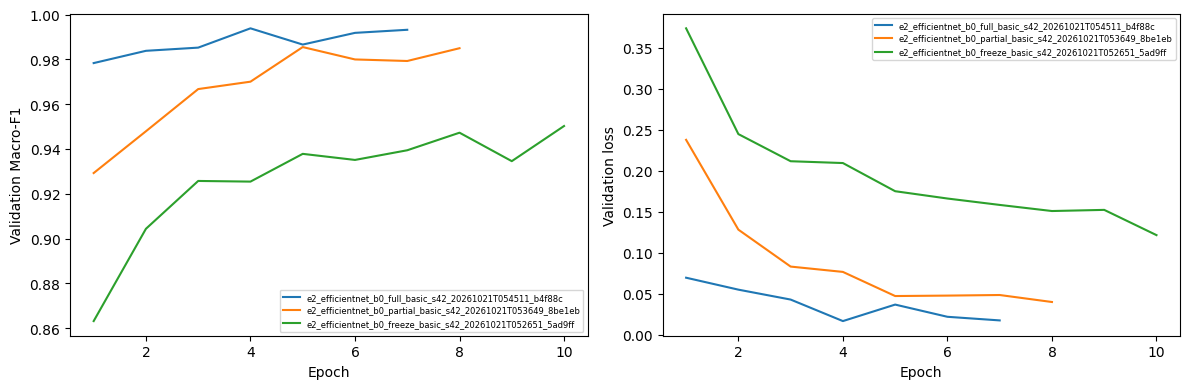

In [8]:
try:
    records = stage_results(PROJECT_ROOT, STAGE)
except (ValueError, FileNotFoundError) as error:
    records = []
    print("尚未满足数据准备或前置阶段条件：", error)
if not records:
    print("尚无本阶段完成的八分类正式结果。")
else:
    table = pd.DataFrame(records).sort_values("val_macro_f1", ascending=False)
    display(table)
    table_dir = PROJECT_ROOT / "outputs" / "tables"
    table_dir.mkdir(parents=True, exist_ok=True)
    table.to_csv(table_dir / f"{STAGE.lower()}_validation.csv", index=False, encoding="utf-8-sig")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for record in records:
        history = pd.read_csv(PROJECT_ROOT / "outputs" / "runs" / record["run_id"] / "history.csv")
        axes[0].plot(history["epoch"], history["val_macro_f1"], label=record["run_id"])
        axes[1].plot(history["epoch"], history["val_loss"], label=record["run_id"])
    axes[0].set(xlabel="Epoch", ylabel="Validation Macro-F1")
    axes[1].set(xlabel="Epoch", ylabel="Validation loss")
    for axis in axes:
        axis.legend(fontsize=6)
    plt.tight_layout()
    figure_dir = PROJECT_ROOT / "outputs" / "figures"
    figure_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_dir / f"{STAGE.lower()}_validation.png", dpi=160, bbox_inches="tight")
    plt.show()


## 4. 保存微调策略选择

查看结果后，将第 1 节 `SAVE_SELECTION` 改为 `True`，重新运行该格，再运行本格。函数要求当前阶段的全部候选都已完成，再按验证集 Macro-F1 选择并写回 `configs/experiments.yaml` 的 `selected_*` 和 `selected_runs`。并列时使用固定规则，详细比较仍保留在表格与记录中。

选择后切换到下一本 Notebook；E3 选定实验就是 Notebook 05 最终评价和 06—07 展示的模型。不要根据测试集结果回头改选。


In [9]:
if not SAVE_SELECTION:
    print("尚未保存新选择；查看结果后将 SAVE_SELECTION 设为 True。")
else:
    try:
        selected = select_best(PROJECT_ROOT, STAGE)
        print("已按验证集结果保存选择：")
        display(selected)
    except (ValueError, FileNotFoundError) as error:
        print("尚不能选择：", error)


已按验证集结果保存选择：


{'run_id': 'e2_efficientnet_b0_full_basic_s42_20261021T054511_b4f88c',
 'stage': 'E2',
 'model': 'efficientnet_b0',
 'finetuning': 'full',
 'augmentation': 'basic',
 'seed': 42,
 'lr': 0.0001,
 'val_macro_f1': 0.9938427923004292,
 'val_accuracy': 0.9955830388692579,
 'val_loss': 0.0164185252067286,
 'best_epoch': 4,
 'epochs_completed': 7,
 'seconds': 1276.9501866250002,
 'dataset_fingerprint': '65e16a548fb193b9d39fdb5114591eeb9fd90d17afbfa6a28865d9b59300a815'}

## 结论记录

- **微调策略的验证表现：** 本实验以 EfficientNet-B0 为统一骨干网络，比较 Freeze、Partial 和 Full 三种微调策略。三种策略的最佳验证集 Macro-F1 分别为 0.9502、0.9855 和 0.9938，验证准确率分别为 96.02%、98.81% 和 99.56%。随着可训练网络层数增加，模型验证集分类表现逐步改善。其中 Full 策略取得最高的 Macro-F1 和准确率，以及最低的验证损失 0.0164。

- **训练效率与收敛情况：** Freeze、Partial 和 Full 分别训练 10、8 和 7 轮，最佳模型分别出现在第 10、5 和 4 轮。三种策略的累计训练时间约为 598.05 秒、501.64 秒和 1276.95 秒。Full 在相对较少的训练轮次内达到最佳验证性能，但因需要更新全部网络参数，训练耗时明显增加。Partial 的验证性能接近 Full，同时具有较低的训练成本。关于过拟合情况，仍需结合逐轮训练损失与验证损失曲线进行判断。

- **最优微调策略选择：** 综合验证集 Macro-F1、Accuracy 和 Loss，选择 Full（全部微调）作为后续实验的主要训练策略。相比 Freeze，Full 的 Macro-F1 提高约 4.36 个百分点；相比 Partial，提高约 0.84 个百分点。尽管计算开销较大，但本研究现阶段优先考虑模型分类效果，因此选择 Full。由于各策略使用了不同的预设学习率，本次结果反映的是相应训练配置的综合效果。

- **后续实验设置及局限性：** 下一阶段固定使用 EfficientNet-B0 和 Full 微调策略，保持八分类标签、数据划分、输入尺寸、随机种子和主要评价指标一致，重点比较不同数据增强策略对模型验证性能的影响。本阶段仅使用随机种子 42，尚未开展多随机种子重复实验。此外，PlantVillage 部分样本缺少可靠的来源分组，仍存在潜在数据泄漏风险，因此较高的验证指标不能直接代表真实环境中的泛化表现。后续需要通过 PlantVillage 独立测试集和 PlantDoc 外部数据进一步评价模型性能。
